In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("../data/customer_churn_sample.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (15, 11)


In [5]:
df.head()


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [6]:
print(df.columns.tolist())

['CustomerID', 'Gender', 'Age', 'TenureMonths', 'SubscriptionType', 'MonthlyCharges', 'TotalCharges', 'ContractType', 'SupportTickets', 'PaymentMethod', 'Churn']


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     str    
 1   Gender            15 non-null     str    
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     str    
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     str    
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     str    
 10  Churn             15 non-null     str    
dtypes: float64(2), int64(3), str(6)
memory usage: 1.4 KB


In [8]:
print(df.isnull().sum())

CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTickets      0
PaymentMethod       0
Churn               0
dtype: int64


C:\Users\BHARGAVI\AppData\Local\Temp\ipykernel_18724\911535252.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in clean_df.select_dtypes(include="object").columns:


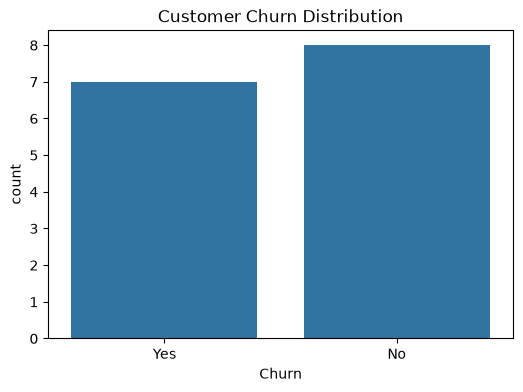

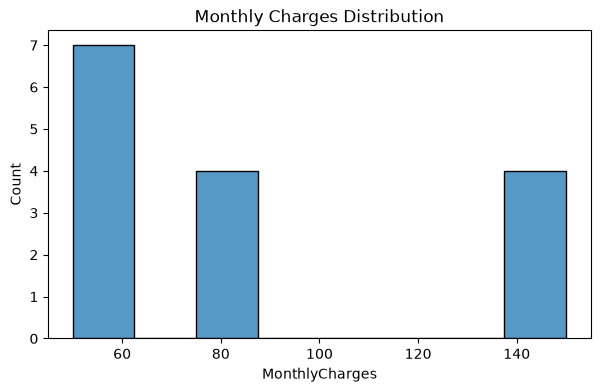

TASK 1 COMPLETED SUCCESSFULLY!
Original dataset shape: (15, 11)
Cleaned dataset shape: (15, 11)
Missing values: 0
Duplicate rows removed: 0
Outlier analysis: {'Age': np.int64(0), 'TenureMonths': np.int64(0), 'MonthlyCharges': np.int64(0), 'TotalCharges': np.int64(0), 'SupportTickets': np.int64(0)}

Cleaned CSV saved successfully!
Data quality report saved successfully!


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create output folders
Path("../reports").mkdir(exist_ok=True)

# Load dataset
df = pd.read_csv("../data/customer_churn_sample.csv")
clean_df = df.copy()

# 1. Remove extra spaces from text columns
for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].str.strip()

# 2. Check missing values
clean_df.replace(r"^\s*$", np.nan, regex=True, inplace=True)
missing_values = clean_df.isnull().sum()

# 3. Check and remove exact duplicate rows
duplicates = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates()

# 4. Check duplicate customer IDs
duplicate_ids = clean_df["CustomerID"].duplicated().sum()

# 5. Identify outliers using IQR method
numeric_cols = clean_df.select_dtypes(include=np.number).columns
outlier_results = {}

for col in numeric_cols:
    Q1 = clean_df[col].quantile(0.25)
    Q3 = clean_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((clean_df[col] < lower) |
             (clean_df[col] > upper)).sum()

    outlier_results[col] = count

# 6. Summary statistics
summary = clean_df.describe()

# 7. Churn distribution
churn_summary = clean_df["Churn"].value_counts()

# 8. Save cleaned dataset
clean_df.to_csv("../data/cleaned_customer_churn.csv", index=False)

# 9. Create visualizations
plt.figure(figsize=(6, 4))
sns.countplot(data=clean_df, x="Churn")
plt.title("Customer Churn Distribution")
plt.savefig("../reports/churn_distribution.png")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=clean_df, x="MonthlyCharges", bins=8)
plt.title("Monthly Charges Distribution")
plt.savefig("../reports/monthly_charges.png")
plt.show()

# 10. Generate data quality report
report = f"""
CUSTOMER CHURN DATA QUALITY REPORT

Total Rows: {len(clean_df)}
Total Columns: {len(clean_df.columns)}

Missing Values:
{missing_values.to_string()}

Exact Duplicate Rows Found: {duplicates}
Exact Duplicate Rows Removed: {duplicates}

Duplicate Customer IDs: {duplicate_ids}

Outlier Counts (IQR Method):
{pd.Series(outlier_results).to_string()}

SUMMARY STATISTICS:
{summary.to_string()}

CHURN DISTRIBUTION:
{churn_summary.to_string()}

Cleaning Decisions:
1. Removed extra spaces from text columns.
2. Checked and reported missing values.
3. Removed exact duplicate rows.
4. Checked duplicate customer IDs.
5. Identified outliers using IQR.
6. Outliers were flagged, not automatically removed.
7. Saved cleaned dataset for further analysis.
"""

with open("../reports/data_quality_report.txt", "w") as file:
    file.write(report)

print("===================================")
print("TASK 1 COMPLETED SUCCESSFULLY!")
print("===================================")
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", clean_df.shape)
print("Missing values:", clean_df.isnull().sum().sum())
print("Duplicate rows removed:", duplicates)
print("Outlier analysis:", outlier_results)
print("\nCleaned CSV saved successfully!")
print("Data quality report saved successfully!")
